In [1]:
import pandas as pd
import os
import tarfile
import urllib






def load_card_fraud_data():
    
    csv_path = 'fraudTrain.csv'
    return pd.read_csv(csv_path)


In [2]:
fraud_data = load_card_fraud_data()
fraud_data.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [3]:
fraud_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [4]:
fraud_data["merchant"].value_counts()

merchant
fraud_Kilback LLC                       4403
fraud_Cormier LLC                       3649
fraud_Schumm PLC                        3634
fraud_Kuhn LLC                          3510
fraud_Boyer PLC                         3493
                                        ... 
fraud_Douglas, DuBuque and McKenzie      775
fraud_Treutel-King                       775
fraud_Medhurst, Labadie and Gottlieb     759
fraud_Reichert-Weissnat                  753
fraud_Hahn, Douglas and Schowalter       727
Name: count, Length: 693, dtype: int64

In [5]:
fraud_data["is_fraud"].value_counts()

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

In [6]:
def fraud_percent_calc(fraud_data):
    mis_conteos = fraud_data["is_fraud"].value_counts()
    
    # Guardar en variables usando el nombre de la categoría
    veces_no_fraude = mis_conteos.loc[0]
    veces_fraude = mis_conteos.loc[1]
    
    fraud_percentage = (veces_fraude/(veces_fraude + veces_no_fraude))* 100
    return fraud_percentage
fraud_percent_calc(fraud_data)

np.float64(0.5788651743883394)

In [7]:
fraud_data.head()


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [8]:
#fraud_data.at_time(time (15, 0)). head (100)

In [9]:
fraud_data.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


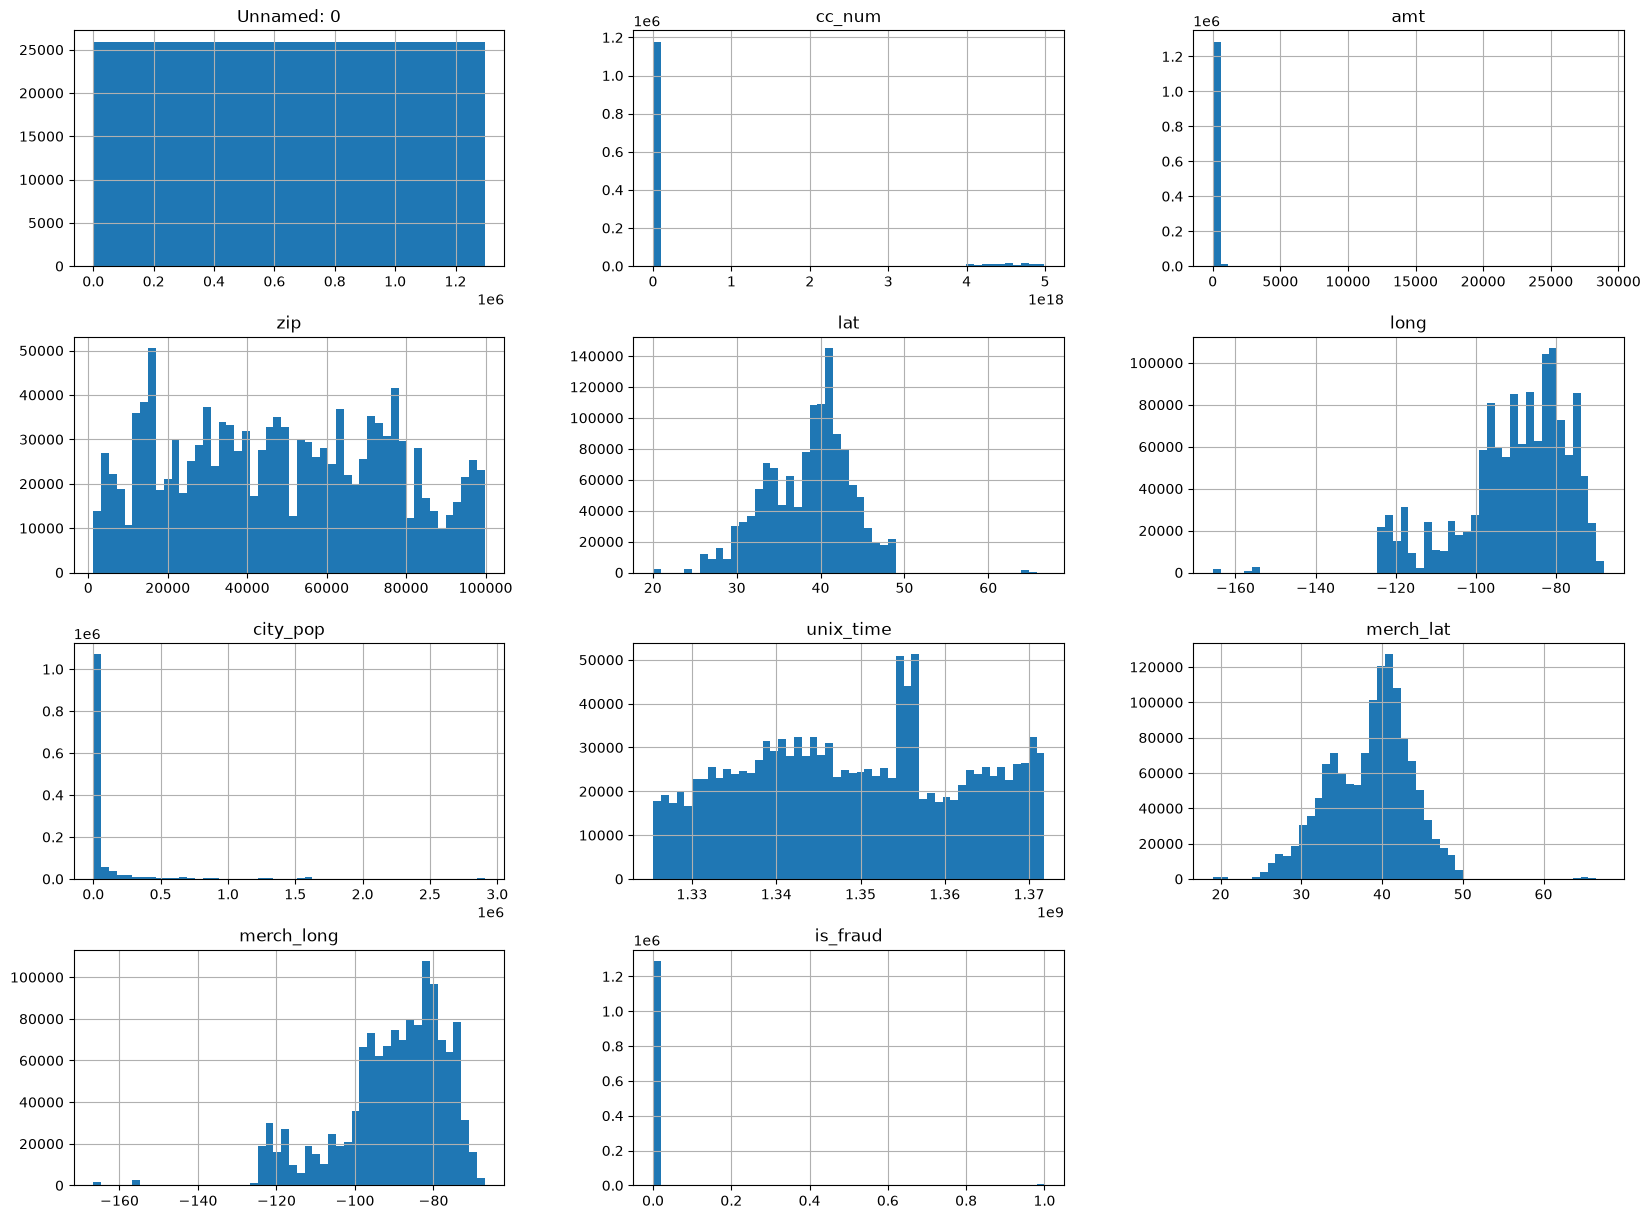

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
fraud_data.hist(bins=50, figsize=(20,15))
plt.show()




In [11]:
group_by_fraud = fraud_data.groupby('merchant')
group_by_fraud.count().head(10)

,Unnamed: 0,trans_date_trans_time,cc_num,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
merchant,,,,,,,,,,,,,,,,,,,,,
fraud_Abbott-Rogahn,1844,1844,1844,1844,1844,1844,1844,1844,1844,1844,...,1844,1844,1844,1844,1844,1844,1844,1844,1844,1844
fraud_Abbott-Steuber,1763,1763,1763,1763,1763,1763,1763,1763,1763,1763,...,1763,1763,1763,1763,1763,1763,1763,1763,1763,1763
fraud_Abernathy and Sons,1751,1751,1751,1751,1751,1751,1751,1751,1751,1751,...,1751,1751,1751,1751,1751,1751,1751,1751,1751,1751
fraud_Abshire PLC,1895,1895,1895,1895,1895,1895,1895,1895,1895,1895,...,1895,1895,1895,1895,1895,1895,1895,1895,1895,1895
"fraud_Adams, Kovacek and Kuhlman",940,940,940,940,940,940,940,940,940,940,...,940,940,940,940,940,940,940,940,940,940
fraud_Adams-Barrows,1746,1746,1746,1746,1746,1746,1746,1746,1746,1746,...,1746,1746,1746,1746,1746,1746,1746,1746,1746,1746
"fraud_Altenwerth, Cartwright and Koss",1904,1904,1904,1904,1904,1904,1904,1904,1904,1904,...,1904,1904,1904,1904,1904,1904,1904,1904,1904,1904
fraud_Altenwerth-Kilback,2503,2503,2503,2503,2503,2503,2503,2503,2503,2503,...,2503,2503,2503,2503,2503,2503,2503,2503,2503,2503
fraud_Ankunding LLC,1923,1923,1923,1923,1923,1923,1923,1923,1923,1923,...,1923,1923,1923,1923,1923,1923,1923,1923,1923,1923


In [12]:
'''fraud_data.groupby('is_fraud').agg({'dob': ['mean','max', 'count', 'sum']})
group_by_frames.mean(numeric_only = True)'''

"fraud_data.groupby('is_fraud').agg({'dob': ['mean','max', 'count', 'sum']})\ngroup_by_frames.mean(numeric_only = True)"

In [13]:
fraud_data.groupby('dob').describe()

Unnamed: 0                                                   \
                count           mean            std      min       25%   
dob                                                                      
1924-10-30      536.0  638242.451493  363982.582989   5953.0  326547.5   
1925-08-29       11.0   95816.090909    1397.177330  93519.0   95587.5   
1926-06-26     2015.0  632056.977667  380079.411752    213.0  295149.0   
1926-07-12     2016.0  643714.535218  371250.690571     60.0  319041.0   
1926-08-27     1513.0  652944.055519  379866.319084    231.0  335721.0   
...               ...            ...            ...      ...       ...   
2004-03-18     1571.0  651386.448122  372691.560122   1282.0  315771.0   
2004-05-08     2915.0  667003.501887  378142.794001    243.0  337682.5   
2004-06-19      483.0  711191.937888  381825.395071   2241.0  380770.0   
2004-12-30     2527.0  658459.119114  375914.608237    981.0  345072.5   
2005-01-29     1959.0  673136.182236  383125.876048    247.0  335867.5   

                                             cc_num                ...  \
                 50%         75%        max   count          mean  ...   
dob                                                                ...   
1924-10-30  637787.5   931457.50  1293815.0   536.0  2.358122e+15  ...   
1925-08-29   95821.0    96024.50    98076.0    11.0  4.492677e+15  ...   
1926-06-26  627570.0   957820.00  1295440.0  2015.0  3.607811e+13  ...   
1926-07-12  653375.0   969543.75  1296307.0  2016.0  4.509142e+15  ...   
1926-08-27  654869.0   995026.00  1296505.0  1513.0  4.502540e+18  ...   
...              ...         ...        ...     ...           ...  ...   
2004-03-18  655613.0   973511.50  1292776.0  1571.0  2.131914e+14  ...   
2004-05-08  684942.0   998138.00  1296666.0  2915.0  4.587657e+18  ...   
2004-06-19  748034.0  1057820.00  1294776.0   483.0  3.557443e+15  ...   
2004-12-30  657306.0   990479.00  1295292.0  2527.0  3.576021e+15  ...   
2005-01-29  702862.0  1008880.00  1296652.0  1959.0  3.648589e+13  ...   

           merch_long            is_fraud                                     \
                  75%        max    count      mean       std  min  25%  50%   
dob                                                                            
1924-10-30 -76.124386 -75.674061    536.0  0.000000  0.000000  0.0  0.0  0.0   
1925-08-29 -76.705128 -76.324569     11.0  1.000000  0.000000  1.0  1.0  1.0   
1926-06-26 -82.403293 -81.917355   2015.0  0.003474  0.058852  0.0  0.0  0.0   
1926-07-12 -81.712295 -81.199722   2016.0  0.000000  0.000000  0.0  0.0  0.0   
1926-08-27 -91.150728 -90.642486   1513.0  0.005948  0.076922  0.0  0.0  0.0   
...               ...        ...      ...       ...       ...  ...  ...  ...   
2004-03-18 -87.534092 -87.046617   1571.0  0.000000  0.000000  0.0  0.0  0.0   
2004-05-08 -87.099607 -86.591981   2915.0  0.001715  0.041387  0.0  0.0  0.0   
2004-06-19 -82.293048 -81.812538    483.0  0.022774  0.149338  0.0  0.0  0.0   
2004-12-30 -95.213548 -94.703059   2527.0  0.006332  0.079335  0.0  0.0  0.0   
2005-01-29 -82.353376 -81.834490   1959.0  0.003573  0.059685  0.0  0.0  0.0   

                      
            75%  max  
dob                   
1924-10-30  0.0  0.0  
1925-08-29  1.0  1.0  
1926-06-26  0.0  1.0  
1926-07-12  0.0  0.0  
1926-08-27  0.0  1.0  
...         ...  ...  
2004-03-18  0.0  0.0  
2004-05-08  0.0  1.0  
2004-06-19  0.0  1.0  
2004-12-30  0.0  1.0  
2005-01-29  0.0  1.0  

[968 rows x 88 columns]

In [14]:
dob_fraud_counts = fraud_data.groupby ('dob'). size ()
freq_dob_fraud = dob_fraud_counts.index [dob_fraud_counts > 2000]
freq_dob_fraud

Index(['1926-06-26', '1926-07-12', '1930-08-13', '1935-02-10', '1936-05-01',
       '1937-03-17', '1938-09-08', '1939-11-04', '1940-08-23', '1942-01-06',
       ...
       '1999-05-31', '1999-06-06', '1999-09-01', '1999-11-30', '1999-12-27',
       '2000-02-20', '2000-06-13', '2003-05-07', '2004-05-08', '2004-12-30'],
      dtype='str', name='dob', length=275)

In [15]:
''' para ver el porcentaje de fraude a lo largo del tiempo del dataset tengo que: 
        dividir el dataset en varias franjas (de months p.e.) y luego a cada franja aplicarle el calculo de %fraude
        '''

' para ver el porcentaje de fraude a lo largo del tiempo del dataset tengo que: \n        dividir el dataset en varias franjas (de months p.e.) y luego a cada franja aplicarle el calculo de %fraude\n        '

In [16]:
fraud_data["fecha"] = pd.to_datetime(fraud_data["unix_time"], unit="s") #paso de unix a datetime el campo de fechas unix_time

In [17]:
fraud_data["months"] = fraud_data["fecha"].dt.month
fraud_data.groupby('months').size().sort_values(ascending=False)

months
5     146875
6     143811
3     143789
12    141060
4     134970
1     104727
2      97657
8      87359
7      86596
9      70652
11     70421
10     68758
dtype: int64

In [18]:


fraud_data.groupby('category').size().sort_values(ascending=False)


category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
dtype: int64

In [19]:
fraud_data["years"] = fraud_data["fecha"].dt.year
fraud_data.groupby('years').size().sort_values(ascending=False)
#me sale que los dos years del dataset son 2012 y 2013 aunque en el otro campo de fechas que esta en string pone 2019 y 2020, no se si he hecho algo mal o si es el dataset que tiene error en las fechas de unixtime vs la de string
fraud_data["days"] = fraud_data["fecha"].dt.day
# Extrae la hora pura (00:00:18)
fraud_data["time"] = fraud_data["fecha"].dt.time
fraud_data['dob_datetime'] = pd.to_datetime(fraud_data['dob'])

In [20]:
fraud_data.groupby('city').size().sort_values(ascending=False)

city
Birmingham     5617
San Antonio    5130
Utica          5105
Phoenix        5075
Meridian       5060
               ... 
Chattanooga       7
Bruce             7
Karns City        7
Claypool          7
Vacaville         7
Length: 894, dtype: int64

In [21]:
''' Tarea 1: 
        dividir dataset en 3 tramos: train, validation y test
'''

' Tarea 1: \n        dividir dataset en 3 tramos: train, validation y test\n'

In [22]:
fraud_data.columns


Index(['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud', 'fecha', 'months', 'years',
       'days', 'time', 'dob_datetime'],
      dtype='str')

In [23]:
#fecha mas antigua
fraud_data['date'] = pd.to_datetime(fraud_data['trans_date_trans_time'])
oldest_date = fraud_data['date'].min()
#fecha mas reciente
newest_date = fraud_data['date'].max()

#output_feature = 'is_fraud'
#input_features = ['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state',
#                    'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'merch_lat', 'merch_long', 'date']

#tiempo entre fecha mas antigua y nueva del dataset
lapse_time = newest_date - oldest_date
partition_time = lapse_time / 3 # para train, validation and test



start_date_training = oldest_date

def get_train_test_set(fraud_data, start_date_training, delta_train=partition_time,
                       delta_validation=2*partition_time, newest_date=newest_date):
    #get the training data
    train_df = fraud_data[(fraud_data["date"] >= start_date_training) & 
                            (fraud_data["date"] < start_date_training+delta_train)]

    #get validation set
    validation_df = fraud_data[(fraud_data["date"] >= start_date_training+delta_train) & 
                            (fraud_data["date"] < start_date_training+delta_validation)]

    #get test set
    test_df = fraud_data[(fraud_data["date"] >= start_date_training+delta_validation) & 
                            (fraud_data["date"] < newest_date)]


    
    
    return (train_df, validation_df, test_df)



In [24]:
'''def card_precision_top_k_day(df_day,top_k):
    
    # This takes the max of the predictions AND the max of label 'is_fraud' for each 'cc_num', 
    # and sorts by decreasing order of fraudulent prediction
    df_day = df_day.groupby('cc_num').max().sort_values(by="predictions", ascending=False).reset_index(drop=False)
            
    # Get the top k most suspicious cards
    df_day_top_k=df_day.head(top_k)
    list_detected_compromised_cards=list(df_day_top_k[df_day_top_k['is_fraud']==1].cc_num)
    
    # Compute precision top k
    card_precision_top_k = len(list_detected_compromised_cards) / top_k
    
    return list_detected_compromised_cards, card_precision_top_k

def card_precision_top_k(predictions_df, top_k, remove_detected_compromised_cards=True):

    # Sort days by increasing order
    list_days=list(predictions_df['days'].unique())
    list_days.sort()
    
    # At first, the list of detected compromised cards is empty
    list_detected_compromised_cards = []
    
    card_precision_top_k_per_day_list = []
    nb_compromised_cards_per_day = []
    
    # For each day, compute precision top k
    for day in list_days:
        
        df_day = predictions_df[predictions_df['days']==day]
        df_day = df_day[['predictions', 'cc_num', 'is_fraud']]
        
        # Let us remove detected compromised cards from the set of daily transactions
        df_day = df_day[df_day.cc_num.isin(list_detected_compromised_cards)==False]
        
        nb_compromised_cards_per_day.append(len(df_day[df_day.is_fraud==1].cc_num.unique()))
        
        detected_compromised_cards, card_precision_top_k = card_precision_top_k_day(df_day,top_k)
        
        card_precision_top_k_per_day_list.append(card_precision_top_k)
        
        # Let us update the list of detected compromised cards
        if remove_detected_compromised_cards:
            list_detected_compromised_cards.extend(detected_compromised_cards)
        
    # Compute the mean
    mean_card_precision_top_k = np.array(card_precision_top_k_per_day_list).mean()
    
    # Returns precision top k per day as a list, and resulting mean
    return nb_compromised_cards_per_day,card_precision_top_k_per_day_list,mean_card_precision_top_k

def performance_assessment(predictions_df, output_feature='is_fraud', 
                           prediction_feature='is_fraud_prediction', top_k_list=[100],
                           rounded=True):
    
    AUC_ROC = metrics.roc_auc_score(predictions_df[output_feature], predictions_df[prediction_feature])
    AP = metrics.average_precision_score(predictions_df[output_feature], predictions_df[prediction_feature])
    
    performances = pd.DataFrame([[AUC_ROC, AP]], 
                           columns=['AUC ROC','Average precision'])
    
    for top_k in top_k_list:
    
        _, _, mean_card_precision_top_k = card_precision_top_k(predictions_df, top_k)
        performances['Card Precision@'+str(top_k)]=mean_card_precision_top_k
        
    if rounded:
        performances = performances.round(3)
    
    return performances

    '''

'def card_precision_top_k_day(df_day,top_k):\n\n    # This takes the max of the predictions AND the max of label \'is_fraud\' for each \'cc_num\', \n    # and sorts by decreasing order of fraudulent prediction\n    df_day = df_day.groupby(\'cc_num\').max().sort_values(by="predictions", ascending=False).reset_index(drop=False)\n\n    # Get the top k most suspicious cards\n    df_day_top_k=df_day.head(top_k)\n    list_detected_compromised_cards=list(df_day_top_k[df_day_top_k[\'is_fraud\']==1].cc_num)\n\n    # Compute precision top k\n    card_precision_top_k = len(list_detected_compromised_cards) / top_k\n\n    return list_detected_compromised_cards, card_precision_top_k\n\ndef card_precision_top_k(predictions_df, top_k, remove_detected_compromised_cards=True):\n\n    # Sort days by increasing order\n    list_days=list(predictions_df[\'days\'].unique())\n    list_days.sort()\n\n    # At first, the list of detected compromised cards is empty\n    list_detected_compromised_cards = []\n\n  

In [25]:
train_df, validation_df, test_df = get_train_test_set(fraud_data, oldest_date) #guardar verdaderamente los valores que retorna la funcion

train_df.shape
validation_df.shape
test_df.shape
fraud_percent_train = train_df['is_fraud'].mean()
fraud_percent_validation = validation_df['is_fraud'].mean()
fraud_percent_test = test_df['is_fraud'].mean()

print(f'the percentage in train set is: {fraud_percent_train}'
      f'\nthe percentage in validation test is: {fraud_percent_validation}'
      f'\nthe percentage in validation test is: {fraud_percent_test}')
print(train_df['date'].dtypes)

the percentage in train set is: 0.006647011388698809
the percentage in validation test is: 0.0049124361253609005
the percentage in validation test is: 0.006041432647096832
datetime64[us]


In [26]:
''' Tarea 2 Baseline de reglas: p.e. fraude si importe > x '''

from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score, average_precision_score

#fraud_data['is_fraud_prediction']=0  #inicializamos columna a 0s
list_params = [5,20,50,100,200,400,600,1000,5000,20000]
precision_list = []
recall_list = []
for x in list_params: 
    #train_df['is_fraud_prediction' + str(x)] = 0 #inicializamos columna para cada x a 0s
    train_df['is_fraud_prediction' + str(x)] = (fraud_data['amt'] > x).astype(int)

    #performances_df = pd.DataFrame()
    #performances_df = fraud_data[['is_fraud', 'is_fraud_prediction']].copy() #comparacion amt > x (ya que amt es una serie de todos los valores indv. de 'amt')
    
    #performances_df['x'] = 200
    #performances_df = performances_df.set_index('x')
    #output_data = performances_df[['is_fraud', 'is_fraud_prediction']]
    output_data = train_df[['is_fraud', 'is_fraud_prediction'+str(x)]]
    print(output_data.head())
    
    matrix = confusion_matrix(train_df['is_fraud'], train_df['is_fraud_prediction'+str(x)])
    precision = precision_score(train_df['is_fraud'], train_df['is_fraud_prediction'+str(x)])
    precision_list.append(precision)
    recall = recall_score(train_df['is_fraud'], train_df['is_fraud_prediction'+str(x)])
    recall_list.append(recall)
    roc_auc = roc_auc_score(train_df['is_fraud'], train_df['is_fraud_prediction'+str(x)])
    pr_auc = average_precision_score(train_df['is_fraud'], train_df['is_fraud_prediction'+str(x)])
    print(f'Confusion matrix for x=: {x}'
          f'\n is: {matrix}'
          f'\n precision is: {precision}'
          f'\n recall is: {recall}'
          f'\n roc-auc is: {roc_auc}'
          f'\n pr-auc is: {pr_auc}')
    







   is_fraud  is_fraud_prediction5
0         0                     0
1         0                     1
2         0                     1
3         0                     1
4         0                     1
Confusion matrix for x=: 5
 is: [[ 48929 341567]
 [    10   2603]]
 precision is: 0.007563122875323241
 recall is: 0.9961729812476081
 roc-auc is: 0.5607363000968845
 pr-auc is: 0.007559616899484648
   is_fraud  is_fraud_prediction20
0         0                      0
1         0                      1
2         0                      1
3         0                      1
4         0                      1
Confusion matrix for x=: 20
 is: [[128086 262410]
 [   481   2132]]
 precision is: 0.008059211769775688
 recall is: 0.8159203980099502
 roc-auc is: 0.5719644397654438
 pr-auc is: 0.00779925448569686
   is_fraud  is_fraud_prediction50
0         0                      0
1         0                      1
2         0                      1
3         0                      0
4         0  

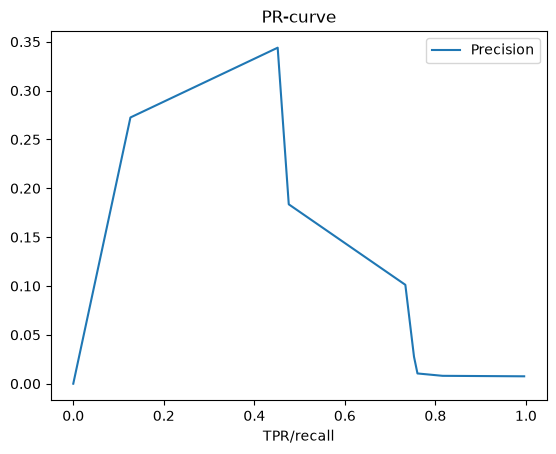

In [27]:

import matplotlib.pyplot as plt


data = {'Precision': precision_list, 'TPR/recall': recall_list}
graph_df = pd.DataFrame(data)


# 2. Generar gráfico de líneas (por defecto)
graph_df.plot(x='TPR/recall', y='Precision', kind='line', title='PR-curve')

# 3. Mostrar el gráfico
plt.show()

In [28]:
def build_features(df):
    out = pd.DataFrame()
    out['amt'] = df['amt']
    out['birth_year'] = df['dob_datetime'].dt.year
    out['day'] = df['date'].dt.day
    return out

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

def logistic_regression(train_df, validation_df):
    X_train = build_features(train_df)
    Y_train = train_df['is_fraud']                  
    print(X_train.dtypes)
    
    
    print(validation_df.dtypes)
    
    X_validation = build_features(validation_df)
    Y_validation = validation_df['is_fraud']
    
    #escalar train y validation
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train[['amt', 'birth_year', 'day']]) #guardamos en vble. nueva
    X_validation_s = scaler.transform(X_validation[['amt', 'birth_year', 'day']])
    
    
    
    # 4. Crear y entrenar el modelo de regresión logística
    modelo = LogisticRegression()
    res = modelo.fit(X_train_s, Y_train)
    #return modelo.fit(X_train_s, Y_train)


    #5 METRICAS (PUEDE QUE ESTE MAL)
    proba = modelo.predict_proba(X_validation_s)[:,1]
    precision = precision_score(validation_df['is_fraud'],(proba > 0.5).astype(int) )

    recall = recall_score(validation_df['is_fraud'], (proba > 0.5).astype(int))

    roc_auc = roc_auc_score(validation_df['is_fraud'], proba )    
    pr_auc = average_precision_score(validation_df['is_fraud'], proba)
    return (precision, recall, roc_auc, pr_auc)
    

precision, recall, roc_auc, pr_auc = logistic_regression(train_df, validation_df)
print(f'\n precision is: {precision}'
          f'\n recall is: {recall}'
          f'\n roc-auc is: {roc_auc}'
          f'\n pr-auc is: {pr_auc}')
    

amt           float64
birth_year      int32
day             int32
dtype: object
Unnamed: 0                        int64
trans_date_trans_time               str
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64


*** TAREA 5: REPETIR PERO CON SPLIT ALEATORIO

In [30]:
def get_train_test_set_RANDOM(fraud_data):
    
    fraud_data_random = fraud_data.sample(frac=1, random_state=42)

    train_len = len(train_df)
    validation_len = len(validation_df)

    
    
    train_rand =  fraud_data_random.iloc[0:train_len] #(iloc incluye inicio pero no el final)
    validation_rand = fraud_data_random.iloc[train_len:(train_len + validation_len)]
    test_rand = fraud_data_random.iloc[(train_len + validation_len):]

    
    
    return (train_rand, validation_rand, test_rand)

In [31]:
train_rand, validation_rand, test_rand = get_train_test_set_RANDOM(fraud_data)
precision_r, recall_r, roc_auc_r, pr_auc_r = logistic_regression(train_rand, validation_rand)

amt           float64
birth_year      int32
day             int32
dtype: object
Unnamed: 0                        int64
trans_date_trans_time               str
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64


In [32]:
regular_fraud_percent = fraud_percent_calc(validation_df)
random_fraud_percent = fraud_percent_calc(validation_rand)

# AP/tasa fraude para normalizar las AP y que sean comparables
print(
    f'\n The normalized AP from the regular validation set is {pr_auc/regular_fraud_percent}'
    f'\n The normalized AP from the random validation set is {pr_auc_r/random_fraud_percent}'
    f'\n cuenta random que me pide el colega para comparar con 0.1736 del regular {(pr_auc_r/random_fraud_percent)*0.58}'
    f'\n The roc-auc from the regular validation set is {roc_auc}'
    f'\n The roc_auc from the random validation set is {roc_auc_r}')



 The normalized AP from the regular validation set is 0.35336944897513
 The normalized AP from the random validation set is 0.3017466457489365
 cuenta random que me pide el colega para comparar con 0.1736 del regular 0.17501305453438315
 The roc-auc from the regular validation set is 0.8525893907211558
 The roc_auc from the random validation set is 0.8360733478734936


Baseline en validacion de cada split (amt como puntuacion)

In [33]:
pr_auc_b = average_precision_score(validation_df['is_fraud'], validation_df['amt'])
pr_auc_b_rand = average_precision_score(validation_rand['is_fraud'], validation_rand['amt'])
print(pr_auc_b, pr_auc_b_rand)

0.17291242438007276 0.1793153692833251


In [34]:
roc_auc_b = roc_auc_score(validation_df['is_fraud'], validation_df['amt'])
roc_auc_b_rand = roc_auc_score(validation_rand['is_fraud'], validation_rand['amt'])
print(roc_auc_b, roc_auc_b_rand)

0.8454391262392439 0.8240693807968297
